In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

stations = pd.read_csv("../data/raw/stations.csv")
print(stations.shape, stations.columns.tolist())
print(stations["City"].value_counts().to_string())

(230, 5) ['StationId', 'StationName', 'City', 'State', 'Status']
City
Delhi                 38
Bengaluru             10
Mumbai                10
Kolkata                7
Patna                  6
Hyderabad              6
Lucknow                5
Faridabad              4
Gurugram               4
Chennai                4
Ghaziabad              4
Noida                  4
Navi Mumbai            3
Jaipur                 3
Meerut                 3
Howrah                 3
Gaya                   2
Thiruvananthapuram     2
Gwalior                2
Chandrapur             2
Greater Noida          2
Amaravati              1
Rajamahendravaram      1
Tirupati               1
Vijayawada             1
Visakhapatnam          1
Guwahati               1
Hajipur                1
Muzaffarpur            1
Chandigarh             1
Ahmedabad              1
Ankleshwar             1
Gandhinagar            1
Nandesari              1
Vapi                   1
Vatva                  1
Ambala                 1
Bahad

In [2]:
for city in ["Chennai", "Guwahati"]:
    print("\n", city)
    display(stations[stations["City"] == city])


 Chennai


,StationId,StationName,City,State,Status
179,TN001,"Alandur Bus Depot, Chennai - CPCB",Chennai,Tamil Nadu,Active
180,TN002,"Manali Village, Chennai - TNPCB",Chennai,Tamil Nadu,Active
181,TN003,"Manali, Chennai - CPCB",Chennai,Tamil Nadu,Active
182,TN004,"Velachery Res. Area, Chennai - CPCB",Chennai,Tamil Nadu,Active



 Guwahati


,StationId,StationName,City,State,Status
5,AS001,"Railway Colony, Guwahati - APCB",Guwahati,Assam,Active


In [3]:
day = pd.read_csv("../data/raw/station_day.csv", parse_dates=["Date"])
print(day.shape, "|", day["Date"].min().date(), "to", day["Date"].max().date())
day = day.merge(stations[["StationId", "StationName", "City", "State"]], on="StationId", how="left")
print(day.columns.tolist())

(108035, 16) | 2015-01-01 to 2020-07-01
['StationId', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket', 'StationName', 'City', 'State']


In [4]:
sub = day[day["City"].isin(["Chennai", "Guwahati"])]
cov = sub.groupby(["City", "StationName"]).agg(
    first=("Date", "min"), last=("Date", "max"),
    rows=("Date", "size"), usable_aqi_days=("AQI", "count"))
cov["calendar_days"] = (cov["last"] - cov["first"]).dt.days + 1
cov["usable_pct"] = (100 * cov["usable_aqi_days"] / cov["calendar_days"]).round(1)
display(cov)

first       last  rows  usable_aqi_days  calendar_days  usable_pct
City     StationName                                                                                                
Chennai  Alandur Bus Depot, Chennai - CPCB   2015-01-01 2020-07-01  2009             1664           2009        82.8
         Manali Village, Chennai - TNPCB     2019-06-19 2020-07-01   379              320            379        84.4
         Manali, Chennai - CPCB              2015-01-01 2020-07-01  2009             1419           2009        70.6
         Velachery Res. Area, Chennai - CPCB 2015-01-01 2020-07-01  2009             1407           2009        70.0
Guwahati Railway Colony, Guwahati - APCB     2019-02-16 2020-07-01   502              495            502        98.6

In [5]:
POLL = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"]
chn = sub[sub["City"] == "Chennai"]
display(chn.groupby("StationName")[POLL + ["AQI"]].apply(lambda d: (100 * d.isna().mean()).round(0)))

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
StationName,,,,,,,,,,,,,
"Alandur Bus Depot, Chennai - CPCB",14.0,100.0,8.0,9.0,9.0,100.0,15.0,9.0,9.0,27.0,25.0,100.0,17.0
"Manali Village, Chennai - TNPCB",8.0,20.0,7.0,7.0,7.0,9.0,7.0,7.0,7.0,7.0,7.0,100.0,16.0
"Manali, Chennai - CPCB",28.0,100.0,25.0,25.0,24.0,26.0,5.0,24.0,100.0,100.0,100.0,100.0,29.0
"Velachery Res. Area, Chennai - CPCB",28.0,100.0,22.0,22.0,21.0,100.0,4.0,27.0,24.0,18.0,18.0,100.0,30.0


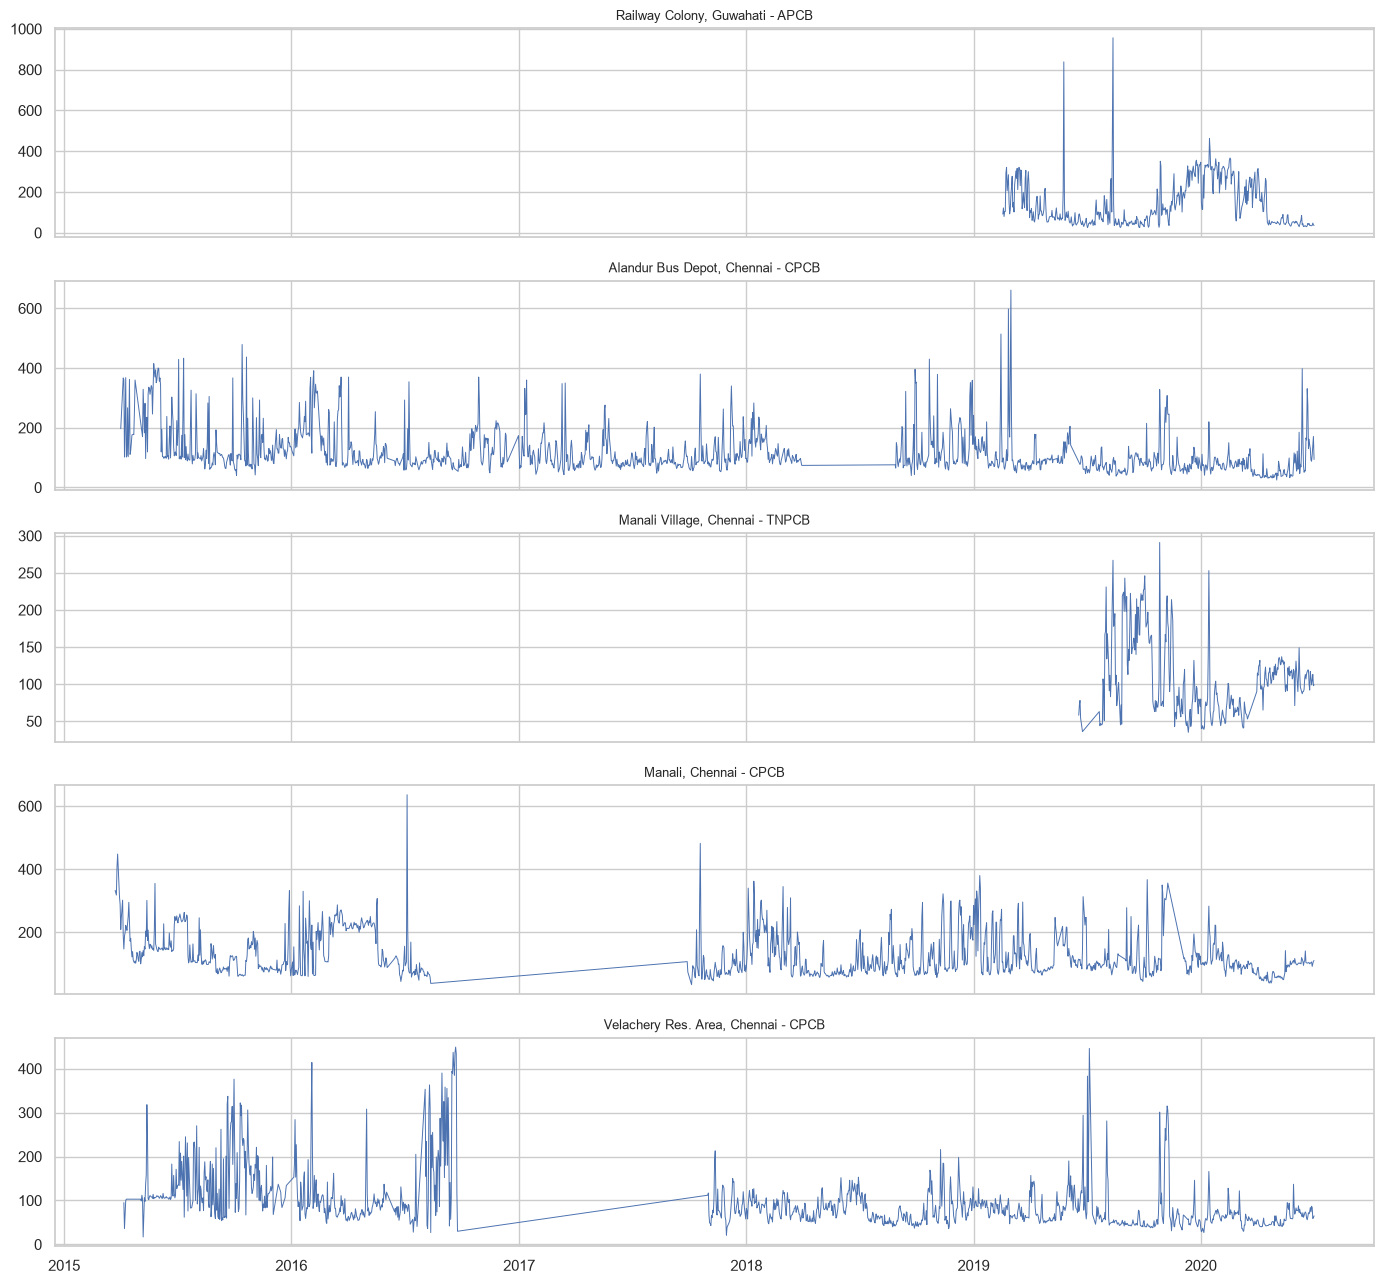

In [6]:
d = sub[sub["AQI"].notna()]
names = d["StationName"].unique()
fig, axes = plt.subplots(len(names), 1, figsize=(14, 2.6 * len(names)), sharex=True)
axes = np.atleast_1d(axes)
for ax, n in zip(axes, names):
    x = d[d["StationName"] == n]
    ax.plot(x["Date"], x["AQI"], lw=0.7); ax.set_title(n, fontsize=9)
plt.tight_layout(); plt.savefig("../figures/01_station_aqi.png", dpi=150); plt.show()